# Closed-system Qualtran resources

Latest manuscript convention: uniform conserved-charge frame, shared preparation, coherent erasure, generic fixed-angle phase-gradient modules, and seven-T Toffolis. Both catalysts are supplied; input-state/catalyst preparation, external Hadamard controls, measurement repetitions and physical error correction are excluded.

The manuscript's three Table VI cases are reproduced first. A separate **3x3 lattice-by-emitter grid at fixed photon cutoff 3** then provides closed-system heatmaps with the same axes and visual style as the open-system notebook. The closed target remains evolution time 1 and initialized-state error 0.001; these differ from the open-system observable workload's time and error allocations.

In [1]:
from pathlib import Path
import os,sys,json,hashlib
os.environ.setdefault('MPLCONFIGDIR','/tmp/tcl-mpl')
os.environ.setdefault('NUMBA_CACHE_DIR','/tmp/tcl-numba')
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'resource_estimation/gqsp.py').is_file())
sys.path.insert(0,str(ROOT/'resource_estimation'))
sys.path.insert(0,str(ROOT/'validation'))
import numpy as np
import pandas as pd
from IPython.display import display,Image,Markdown
import gqsp as resources
import validation as validate


In [2]:
tables=resources.ensure_resources('closed')
display(tables['II'])
display(tables['VI'])


,L,N,n_max,b,B,a,cU_direct,cU_row,cW_direct,cW_row,cW_pair,saving_percent,P_ph,Q_direct,Q_pair
0,16,1,3,20,19,108,2308,2496,3690,4066,3874,4.749613,32,297,329
1,64,2,7,23,22,128,8834,10046,14410,16834,15682,8.111210,192,613,805
2,256,4,15,27,26,154,52212,58864,83720,97024,90880,7.878521,1024,2399,3423


,L,N,n_max,K,m,two_eta_bound,bound_rounded_up,T_U_direct,T_U_pair,Q_U_direct,Q_U_pair
0,16,1,3,62,22,2.086984e-08,2.0870e-08,3386082,3545794,320,352
1,64,2,7,485,25,2.363641e-08,2.3637e-08,99474508,108111388,639,831
2,256,4,15,4863,28,2.933821e-08,2.9339e-08,5718208314,6205675434,2428,3452


## Derived precision and arithmetic versus synthesized T counts

The planner derives b/B, Bessel-tail-certified degree K and rotation precision m; these are not loaded from printed manuscript totals. Actual forward/inverse queries and axial rotation modules are decomposed and their repeated schedules aggregated. No large flattened gate list or many-body statevector is constructed.

In [3]:
rows=[]
for job in resources.CLOSED_CASES:
    r=json.loads(resources._point_path('closed',job).read_text());p=r['plan']
    assert r['sources_sha256']==resources.source_hashes()
    for mode,d in r['modes'].items():
        rows.append(dict(L=p['L'],N=p['N'],n_max=p['n_max'],mode=mode,b=p['b'],B=p['B'],K=p['K'],m=p['m'],
            walk_Toffolis=d['walk']['coherent_ccx'],T=d['evolution']['T'],qubits=d['evolution']['peak_logical_qubits']))
display(pd.DataFrame(rows))


,L,N,n_max,mode,b,B,K,m,walk_Toffolis,T,qubits
0,16,1,3,direct,20,19,62,22,3690,3386082,320
1,16,1,3,paired,20,19,62,22,3874,3545794,352
2,16,1,3,sparse,20,19,62,22,4066,3712450,352
3,64,2,7,direct,23,22,485,25,14410,99474508,639
4,64,2,7,paired,23,22,485,25,15682,108111388,831
5,64,2,7,sparse,23,22,485,25,16834,115933468,831
6,256,4,15,direct,27,26,4863,28,83720,5718208314,2428
7,256,4,15,paired,27,26,4863,28,90880,6205675434,3452
8,256,4,15,sparse,27,26,4863,28,97024,6623971242,3452


## Closed-system heatmaps: fixed cutoff, independent lattice and emitter axes

Columns are lattices **4x4, 4x8, 8x8**; rows are emitters per cavity **1, 2, 4**. Photon cutoff is **3 throughout**, with $T=1$, target error $10^{-3}$, $t=0.05$, $g=\nu=1$, $\Delta=0$, and the uniform potential removed. Precision and GQSP degree are derived separately at each point.

Existing source-hashed Table II and Figure 7 walk counts are reused where available. Missing shared walks are compiled. Evolution T totals combine their measured coherent counts with measured fixed-angle rotation modules according to the actual GQSP schedule. The extra rotation catalyst is included; its adder fits inside the verified clean-workspace bank. The highlighted cell is the first Table VI case. These are generic resource bounds, not numerical many-body state simulations or a new printed manuscript table.

,lattice,Lx,Ly,L,N,n_max,tau,epsilon,b,B,K,m,T_U_direct,T_U_pair,Q_U_direct,Q_U_pair
0,4x4,4,4,16,1,3,1,0.001,20,19,62,22,3386082,3545794,320,352
1,4x4,4,4,16,2,3,1,0.001,20,19,95,22,5437922,5682642,335,367
2,4x4,4,4,16,4,3,1,0.001,21,20,157,23,12230596,12635028,381,413
3,4x8,4,8,32,1,3,1,0.001,21,20,106,22,9789346,10347330,385,449
4,4x8,4,8,32,2,3,1,0.001,21,20,168,23,16431996,17316348,417,481
5,4x8,4,8,32,4,3,1,0.001,22,21,287,24,39658626,41169394,495,559
6,8x8,8,8,64,1,3,1,0.001,22,21,189,23,31557120,33568080,498,626
7,8x8,8,8,64,2,3,1,0.001,22,21,308,24,54763366,58040486,562,690
8,8x8,8,8,64,4,3,1,0.001,23,22,541,25,139362608,145118848,704,832


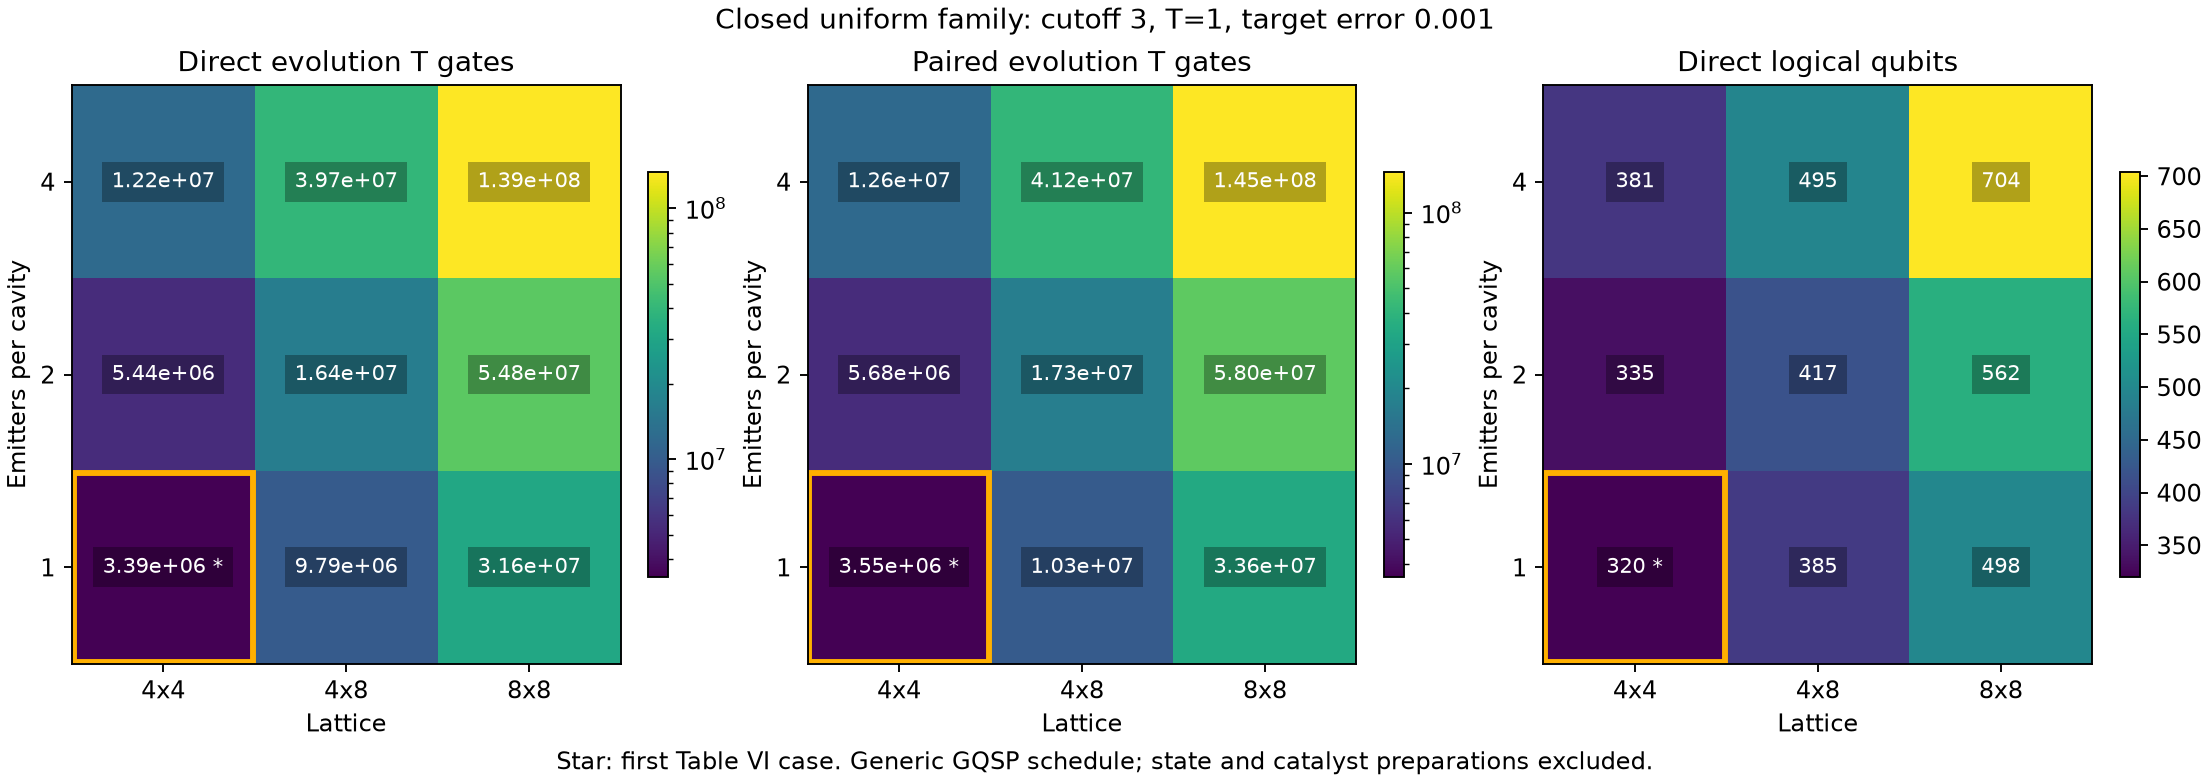

In [4]:
RECOMPILE_CLOSED_GRID=False
closed_grid=resources.closed_heatmap_table(force=RECOMPILE_CLOSED_GRID)
display(closed_grid)
assert len(closed_grid)==9
assert closed_grid.n_max.eq(3).all()
assert set(closed_grid.N)=={1,2,4}
resources.resource_heatmaps()
display(Image(filename=str(resources.RESULTS/'closed_resource_heatmaps.png')))


The validation notebook separately generates the first case's numerical phases and checks its spectral response. The larger resource cases remain generic phase-independent schedules. The original nonuniform and historical development notebooks remain in the working bundle; this curated notebook focuses on the current uniform manuscript examples.